In [10]:
import pandas as pd
import numpy as np

In [11]:
df=pd.read_csv('28X28PIXELS.csv')
df.head(5)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [12]:
import matplotlib.pyplot as plt
df.shape

(42000, 785)

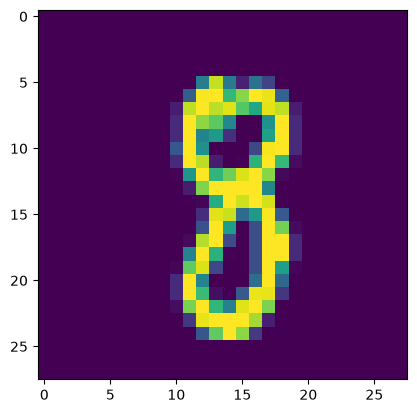

In [13]:
plt.imshow(df.iloc[23401,1:].values.reshape(28,28))

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [15]:
x=df.iloc[:,1:]
y=df.iloc[:,0]
xtrain,xtest,ytrain,ytest=train_test_split(x,y,train_size=0.8)

In [16]:
mod=KNeighborsClassifier()
mod.fit(xtrain,ytrain)
print(accuracy_score(ytest,mod.predict(xtest)))


0.9648809523809524


In [17]:
from sklearn.decomposition import PCA

In [18]:
pca=PCA(n_components=None)
xtrain_all=pca.fit_transform(xtrain)
xtest_all=pca.transform(xtest)

In [19]:
mod=KNeighborsClassifier()
mod.fit(xtrain_all,ytrain)
print(accuracy_score(ytest,mod.predict(xtest_all)))

0.9648809523809524


In [21]:
for i in range(1,785) :
    pca=PCA(n_components=i)
    xtrain_all=pca.fit_transform(xtrain)
    xtest_all=pca.transform(xtest)

    mod=KNeighborsClassifier()
    mod.fit(xtrain_all,ytrain)
    print(f"COLUMN = {i} ACCURECY = {accuracy_score(ytest,mod.predict(xtest_all))}")

COLUMN = 1 ACCURECY = 0.26666666666666666
COLUMN = 2 ACCURECY = 0.41345238095238096
COLUMN = 3 ACCURECY = 0.49202380952380953
COLUMN = 4 ACCURECY = 0.6271428571428571
COLUMN = 5 ACCURECY = 0.7346428571428572
COLUMN = 6 ACCURECY = 0.8186904761904762
COLUMN = 7 ACCURECY = 0.8675
COLUMN = 8 ACCURECY = 0.8923809523809524
COLUMN = 9 ACCURECY = 0.9069047619047619
COLUMN = 10 ACCURECY = 0.9233333333333333
COLUMN = 11 ACCURECY = 0.9319047619047619
COLUMN = 12 ACCURECY = 0.9411904761904762
COLUMN = 13 ACCURECY = 0.9511904761904761
COLUMN = 14 ACCURECY = 0.9538095238095238
COLUMN = 15 ACCURECY = 0.9544047619047619
COLUMN = 16 ACCURECY = 0.959047619047619
COLUMN = 17 ACCURECY = 0.9603571428571429
COLUMN = 18 ACCURECY = 0.9633333333333334
COLUMN = 19 ACCURECY = 0.9641666666666666
COLUMN = 20 ACCURECY = 0.9657142857142857
COLUMN = 21 ACCURECY = 0.9673809523809523
COLUMN = 22 ACCURECY = 0.9678571428571429
COLUMN = 23 ACCURECY = 0.9692857142857143
COLUMN = 24 ACCURECY = 0.9702380952380952
COLUMN = 25

KeyboardInterrupt: 

In [23]:
pca=PCA(n_components=None)
xtrain_all=pca.fit_transform(xtrain)
xtest_all=pca.transform(xtest)
var_ratio=pca.explained_variance_ratio_

In [35]:
data90 = None
data95 = None
cum = 0

for idx,i in enumerate(var_ratio) :
    cum=cum+i
    if(data90 is None and cum>=0.9) :
        data90=idx
    if(data95 is None and cum>=0.95) :
        data95=idx
        break
print(f"Components for 90% = {data90}, Components for 95% = {data95}")

Components for 90% = 86, Components for 95% = 152


In [42]:
def pca_knn(n,xtrain,xtest,ytest,ytrain) : 
    pca=PCA(n_components=n)
    xtrain_n=pca.fit_transform(xtrain)
    xtest_n=pca.transform(xtest)

    mod=KNeighborsClassifier()
    mod.fit(xtrain_n,ytrain)
    acc_str=f"ACCURACY = {accuracy_score(ytest,mod.predict(xtest_n))}"
    return acc_str
    
    


In [45]:
res=pca_knn(86,xtrain,xtest,ytest,ytrain)
print(res)

ACCURACY = 0.97


0.9